# RQ1: Predicting meal-level glycemic response 

**Goal.** Predict the 0 to 120 min positive iAUC of each eligible meal from nested feature sets, and compare three model families under participant-grouped cross-validation.

| Set | Features | Target |
|---|---|---|
| **M1** | food macros (carbs, protein, fat, fiber) | raw |
| **M2** | M1 + pre-meal glucose (mean, slope, last, SD), heart rate, physical activity, meal context | raw |
| **M3** | M2 + blood biomarkers / demographics (age, BMI, HbA1c, fasting glucose, insulin) | raw |
| **M4** | M3 + gut-health scores (gut-matched participants only) | raw |

**Models:** Ridge, XGBoost. **Evaluation:** 5-fold participant-grouped outer CV with nested grouped CV for hyperparameters; pooled out-of-fold RMSE, MAE, R², mean participant MAE and more.

**Targets.** Ridge and XGBoost are each run twice: on **`y_raw`** (iAUC in mg/dL·min) 

In [ ]:
import os
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from IPython.display import display

from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import GammaRegressor, Ridge
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, median_absolute_error, r2_score,
)
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_predict
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import xgboost as xgb
HAVE_XGB = True

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# ---------------------------------------------------------------- settings
SEED = 32
DATA_DIR = Path(os.environ.get(
    "CGMACROS_DIR",
    "/Users/pavithraa/Desktop/BME_Data_Science/Project/Glucose-macros-data/"
    "cgmacros-code/cgmacros-data/CGMacros",
))
OUT_DIR = Path("results_log_target")
OUT_DIR.mkdir(exist_ok=True)

EXCLUDED_SUBJECTS = {18: "Repeated 900/901-minute timestamp jumps; timing unresolved"}

# Meal-window rules (identical to code_explore.ipynb)
BASELINE_MINUTES = 15
RESPONSE_MINUTES = 120
PREVIOUS_FOOD_MINUTES = 180
MAX_MISSING_RUN = 5
MIN_BASELINE_VALID = 12      # of 15 baseline minutes
MIN_RESPONSE_VALID = 97      # of 121 response minutes (80%)

# Pre-meal feature window
PREMEAL_MINUTES = 30
PREMEAL_MIN_VALID = 24       # 80% of the 30 minutes

# Sanity checks against the original analysis (set to None to disable)
EXPECTED_CANDIDATES = 1667
EXPECTED_MEALS = 1139

# Features with lower coverage than this are dropped from premeal/activity groups
MIN_FEATURE_COVERAGE = 0.40
# Optional extra lipid markers for M3 (kept off to match the original five)
INCLUDE_LIPIDS = False

OUTER_FOLDS = 5
INNER_FOLDS = 5

print("DATA_DIR:", DATA_DIR, "| exists:", DATA_DIR.exists())
print("pandas", pd.__version__, "| numpy", np.__version__, "| xgboost available:", HAVE_XGB)

DATA_DIR: /Users/pavithraa/Desktop/BME_Data_Science/Project/Glucose-macros-data/cgmacros-code/cgmacros-data/CGMacros | exists: True
pandas 3.1.0 | numpy 2.5.4 | xgboost available: True


## 1. Load and clean participant-level tables
Same checks as the original notebook: IDs must be unique integers, documented erroneous lab values (LDL = 800, VLDL = 400) are set to missing, and each participant is flagged for whether a gut profile exists.

In [2]:
def load_metadata(filename):
    """Load a table and validate IDs so later joins cannot duplicate meals."""
    path = DATA_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"File not found: {path}")

    table = pd.read_csv(path, encoding="utf-8-sig")
    table.columns = table.columns.str.strip()
    if table.columns.duplicated().any():
        raise ValueError(f"{filename}: duplicate column names after stripping")
    if "subject" not in table.columns:
        raise ValueError(f"{filename}: missing subject column")

    ids = pd.to_numeric(table["subject"], errors="coerce")
    if ids.isna().any() or not np.isfinite(ids).all():
        raise ValueError(f"{filename}: missing or invalid participant IDs")
    if (ids % 1 != 0).any():
        raise ValueError(f"{filename}: non-integer participant IDs")

    table["subject"] = ids.astype(int)
    if table["subject"].duplicated().any():
        raise ValueError(f"{filename}: repeated participant IDs")
    return table


bio_raw = load_metadata("bio.csv")
gut_raw = load_metadata("gut_health_test.csv")
bio, gut = bio_raw.copy(), gut_raw.copy()

# Documented erroneous values -> missing (modeling copy only)
quality_flags = []
for column, error_value in [("LDL (Cal)", 800), ("VLDL (Cal)", 400)]:
    if column not in bio.columns:
        continue
    mask = bio[column].eq(error_value)
    for subject in bio.loc[mask, "subject"]:
        quality_flags.append({"subject": int(subject), "variable": column,
                              "original_value": error_value, "action": "Set to missing"})
    bio.loc[mask, column] = np.nan

gut_columns = gut.columns.drop("subject").tolist()
gut_subjects = set(gut.loc[gut[gut_columns].notna().any(axis=1), "subject"])
bio["has_gut_data"] = bio["subject"].isin(gut_subjects)

print("bio shape:", bio.shape, "| gut shape:", gut.shape)
print("Participants with gut data:", int(bio["has_gut_data"].sum()),
      "| without:", int((~bio["has_gut_data"]).sum()))
print("\nBlood/demographic columns:", [c for c in bio.columns if c != "subject"])
print("\nQuality flags:")
print(pd.DataFrame(quality_flags).to_string(index=False) if quality_flags else "none")

bio shape: (45, 25) | gut shape: (47, 23)
Participants with gut data: 42 | without: 3

Blood/demographic columns: ['Age', 'Gender', 'BMI', 'Body weight', 'Height', 'Self-identify', 'A1c PDL (Lab)', 'Fasting GLU - PDL (Lab)', 'Insulin', 'Triglycerides', 'Cholesterol', 'HDL', 'Non HDL', 'LDL (Cal)', 'VLDL (Cal)', 'Cho/HDL Ratio', 'Collection time PDL (Lab)', '#1 Contour Fingerstick GLU', 'Time (t)', '#2 Contour Fingerstick GLU', 'Time (t).1', '#3 Contour Fingerstick GLU', 'Time (t).2', 'has_gut_data']

Quality flags:
 subject   variable  original_value         action
      12  LDL (Cal)             800 Set to missing
      12 VLDL (Cal)             400 Set to missing


## 2. Load each participant file once
The original notebook re-read every CSV in about ten different cells. Here each file is read **once**, headers are harmonised, and the cleaned frame is cached in `frames[subject]`.

Activity columns differ between files (some have `METs`/`Steps`, others `Calories (Activity)`/`Intensity`), so headers are normalised to `METs`, `Steps`, `Calories_Activity`, `Intensity` and the schema of each file is audited before any feature is built.

In [3]:
macro_columns = ["Carbs", "Protein", "Fat", "Fiber"]
ACTIVITY_COLUMNS = ["METs", "Steps", "Calories_Activity", "Intensity"]

# Keys are header text lower-cased with everything except letters removed.
COLUMN_ALIASES = {
    "mets": "METs",
    "steps": "Steps",
    "caloriesactivity": "Calories_Activity",
    "calorieactivity": "Calories_Activity",
    "activitycalories": "Calories_Activity",
    "intensity": "Intensity",
    "hr": "HR",
}


def canonical_name(name):
    return COLUMN_ALIASES.get(re.sub(r"[^a-z]", "", name.casefold()), name)


# If a file stores Intensity as words, map them to an ordinal scale.
INTENSITY_LEVELS = {"sedentary": 0, "light": 1, "lightly active": 1, "lightlyactive": 1,
                    "moderate": 2, "fairly active": 2, "moderately active": 2,
                    "vigorous": 3, "high": 3, "very active": 3, "veryactive": 3}


def subject_from_path(path):
    return int(re.fullmatch(r"CGMacros-(\d+)", path.stem).group(1))


def read_participant(path):
    """Read one file, harmonise headers, sort by time. Returns (frame, schema)."""
    frame = pd.read_csv(path, encoding="utf-8-sig")
    frame.columns = [canonical_name(c.strip()) for c in frame.columns]
    if frame.columns.duplicated().any():
        raise ValueError(f"{path.name}: duplicate headers after harmonising")

    required = {"Timestamp", "Meal Type", "Libre GL"}
    if required - set(frame.columns):
        raise ValueError(f"{path.name}: missing {sorted(required - set(frame.columns))}")

    frame["Timestamp"] = pd.to_datetime(frame["Timestamp"], errors="raise")
    frame = frame.sort_values("Timestamp").reset_index(drop=True)

    if "Intensity" in frame.columns and frame["Intensity"].dtype == object:
        words = frame["Intensity"].astype("string").str.strip().str.lower().astype(object).map(INTENSITY_LEVELS)
        frame["Intensity"] = pd.to_numeric(frame["Intensity"], errors="coerce").fillna(words)

    numeric = ["Libre GL", "HR", "Calories", *macro_columns, *ACTIVITY_COLUMNS]
    schema = {"subject": subject_from_path(path), "rows": len(frame)}
    for column in ["HR", *ACTIVITY_COLUMNS]:
        schema[f"has_{column}"] = column in frame.columns
    for column in numeric:
        if column in frame.columns:
            frame[column] = pd.to_numeric(frame[column], errors="coerce")
        elif column in ["HR", *ACTIVITY_COLUMNS]:
            frame[column] = np.nan          # absent optional signal -> missing
    for column in ["HR", *ACTIVITY_COLUMNS]:
        schema[f"{column}_nonnull_pct"] = round(100 * frame[column].notna().mean(), 1)
    return frame, schema


participant_files = sorted(DATA_DIR.rglob("CGMacros-*.csv"))
if not participant_files:
    raise FileNotFoundError(f"No CGMacros participant CSVs found under {DATA_DIR}")

frames, schema_rows = {}, []
for path in participant_files:
    subject = subject_from_path(path)
    if subject in EXCLUDED_SUBJECTS:
        continue
    if subject in frames:
        raise ValueError(f"Multiple files for participant {subject}")
    frames[subject], schema = read_participant(path)
    schema_rows.append(schema)

schema_df = pd.DataFrame(schema_rows).sort_values("subject").reset_index(drop=True)

print("Participant files found:", len(participant_files))
print("Excluded:", EXCLUDED_SUBJECTS)
print("Participants loaded:", len(frames))

print("\nActivity-signal schemas (True = column present in the file):")
flag_cols = [f"has_{c}" for c in ["HR", *ACTIVITY_COLUMNS]]
print(schema_df.groupby(flag_cols).size().rename("participants").reset_index().to_string(index=False))

print("\nShare of minutes with a value, per signal (across participants):")
print(schema_df[[f"{c}_nonnull_pct" for c in ["HR", *ACTIVITY_COLUMNS]]].describe().round(1).to_string())

Participant files found: 45
Excluded: {18: 'Repeated 900/901-minute timestamp jumps; timing unresolved'}
Participants loaded: 44

Activity-signal schemas (True = column present in the file):
 has_HR  has_METs  has_Steps  has_Calories_Activity  has_Intensity  participants
   True     False      False                   True           True            11
   True      True      False                   True          False            32
   True      True       True                  False          False             1

Share of minutes with a value, per signal (across participants):
       HR_nonnull_pct  METs_nonnull_pct  Steps_nonnull_pct  Calories_Activity_nonnull_pct  Intensity_nonnull_pct
count            44.0              44.0               44.0                           44.0                   44.0
mean             88.8              71.7                2.3                           93.7                   24.3
std              11.7              42.1               15.1                      

## 3. Meal-window eligibility (target: 1,139 meals)
Every logged food entry (all labels, snacks included) must have: a 15-min pre-meal baseline (≥12 valid minutes), a 120-min response (≥97 of 121 valid minutes, both endpoints present), no food in the previous 180 min or the next 120 min, enough recording history, and no glucose gap longer than 5 min. Rules are unchanged from the original notebook.

In [4]:
def longest_missing_run(series):
    """Prevent acceptable overall coverage from hiding a long gap."""
    missing = series.isna()
    runs = missing.ne(missing.shift()).cumsum()
    return int(missing.groupby(runs).sum().max()) if len(series) else 0


def audit_meal_windows(subject, frame):
    """Flag each food entry using timing and Libre coverage."""
    labels = frame["Meal Type"].astype("string").str.strip().str.lower()
    is_food = labels.notna() & labels.ne("")
    events = frame.loc[is_food, ["Timestamp"]].copy()
    events["meal_type"] = labels.loc[is_food]
    events["previous_gap"] = events["Timestamp"].diff().dt.total_seconds() / 60
    events["next_gap"] = (events["Timestamp"].shift(-1) - events["Timestamp"]).dt.total_seconds() / 60

    glucose = pd.Series(frame["Libre GL"].to_numpy(), index=pd.DatetimeIndex(frame["Timestamp"]))
    rows = []
    for event in events.itertuples(index=False):
        time_ = event.Timestamp
        baseline = glucose.reindex(pd.date_range(
            time_ - pd.Timedelta(minutes=BASELINE_MINUTES), periods=BASELINE_MINUTES, freq="min"))
        response = glucose.reindex(pd.date_range(
            time_, periods=RESPONSE_MINUTES + 1, freq="min"))
        window = pd.concat([baseline, response])

        flags = {
            "previous_food_too_close": pd.notna(event.previous_gap) and event.previous_gap < PREVIOUS_FOOD_MINUTES,
            "additional_food_in_response": pd.notna(event.next_gap) and event.next_gap <= RESPONSE_MINUTES,
            "insufficient_recording_history": time_ - pd.Timedelta(minutes=PREVIOUS_FOOD_MINUTES) < glucose.index.min(),
            "insufficient_baseline": baseline.notna().sum() < MIN_BASELINE_VALID,
            "insufficient_response": response.notna().sum() < MIN_RESPONSE_VALID,
            "missing_response_endpoint": pd.isna(response.iloc[0]) or pd.isna(response.iloc[-1]),
            "long_glucose_gap": longest_missing_run(window) > MAX_MISSING_RUN,
        }
        rows.append({"subject": subject, "event_timestamp": time_, "meal_type": event.meal_type,
                     "previous_gap_min": event.previous_gap, **flags, "eligible": not any(flags.values())})
    return pd.DataFrame(rows)


flag_columns = ["previous_food_too_close", "additional_food_in_response",
                "insufficient_recording_history", "insufficient_baseline",
                "insufficient_response", "missing_response_endpoint", "long_glucose_gap"]

meal_eligibility = pd.concat(
    [audit_meal_windows(subject, frame) for subject, frame in frames.items()],
    ignore_index=True)

print("Candidate food entries:", len(meal_eligibility))
print("Eligible entries:", int(meal_eligibility["eligible"].sum()))
print("Participants with eligible entries:",
      meal_eligibility.loc[meal_eligibility["eligible"], "subject"].nunique())
print("\nFlag counts (an entry can have several flags):")
print(meal_eligibility[flag_columns].sum().to_string())
print("\nEligibility by meal type:")
print(meal_eligibility.groupby("meal_type")["eligible"]
      .agg(candidate_entries="size", eligible_entries="sum").to_string())

if EXPECTED_CANDIDATES is not None:
    print("\nCandidates match the original notebook:", len(meal_eligibility) == EXPECTED_CANDIDATES)

Candidate food entries: 1667
Eligible entries: 1139
Participants with eligible entries: 43

Flag counts (an entry can have several flags):
previous_food_too_close           334
additional_food_in_response       245
insufficient_recording_history     21
insufficient_baseline               7
insufficient_response              21
missing_response_endpoint          17
long_glucose_gap                   16

Eligibility by meal type:
           candidate_entries  eligible_entries
meal_type                                     
breakfast                426               409
dinner                   479               247
lunch                    425               368
snack                    298               101
snack 1                    1                 1
snacks                    38                13

Candidates match the original notebook: True


## 4. Outcome: positive iAUC per eligible meal
Libre glucose is capped at 400 mg/dL (a no-op inside eligible windows in the original analysis), short internal gaps (≤5 min) are interpolated in time, and the positive area above the 15-min baseline mean is integrated with exact baseline crossings. Outcome unit: mg/dL·min.

In [5]:
def fill_short_internal_gaps(series, max_gap=5):
    """Fill only entire internal gaps within the accepted length."""
    missing = series.isna()
    runs = missing.ne(missing.shift()).cumsum()
    run_lengths = missing.groupby(runs).transform("sum")
    interpolated = series.interpolate(method="time", limit_area="inside")
    return series.where(~(missing & run_lengths.le(max_gap)), interpolated)


def positive_area(values, baseline):
    """Integrate above baseline, accounting for crossings between minutes."""
    excursions = np.asarray(values, dtype=float) - baseline
    left, right = excursions[:-1], excursions[1:]
    areas = np.zeros(len(left))
    above = (left >= 0) & (right >= 0)
    areas[above] = (left[above] + right[above]) / 2
    crossing = ((left < 0) & (right > 0)) | ((left > 0) & (right < 0))
    positive_height = np.maximum(left[crossing], right[crossing])
    areas[crossing] = positive_height ** 2 / (2 * np.abs(right[crossing] - left[crossing]))
    return float(areas.sum())


eligible_events = meal_eligibility.loc[meal_eligibility["eligible"]].copy()
eligible_events["meal_type"] = eligible_events["meal_type"].replace(
    {"snacks": "snack", "snack 1": "snack"})

iauc_rows = []
for subject, frame in frames.items():
    events = eligible_events.loc[eligible_events["subject"].eq(subject)]
    if events.empty:
        continue
    raw = pd.Series(frame["Libre GL"].to_numpy(),
                    index=pd.DatetimeIndex(frame["Timestamp"])).sort_index()

    for event in events.itertuples(index=False):
        time_ = event.event_timestamp
        raw_baseline = raw.reindex(pd.date_range(time_ - pd.Timedelta(minutes=BASELINE_MINUTES),
                                                 periods=BASELINE_MINUTES, freq="min"))
        raw_response = raw.reindex(pd.date_range(time_, periods=RESPONSE_MINUTES + 1, freq="min"))

        response = fill_short_internal_gaps(raw_response.clip(upper=400))
        if response.isna().any():
            raise ValueError(f"Unfilled response gap: subject {subject}, {time_}")
        baseline = float(raw_baseline.clip(upper=400).mean())

        iauc_rows.append({
            "subject": subject,
            "event_timestamp": time_,
            "meal_type": event.meal_type,
            "previous_gap_min": event.previous_gap_min,
            "baseline_capped": baseline,
            "iauc_capped": positive_area(response, baseline),
            "response_minutes_filled": int(raw_response.isna().sum()),
        })

meal_outcomes = pd.DataFrame(iauc_rows)

print("Meals selected:", len(meal_outcomes), "| participants:", meal_outcomes["subject"].nunique())
print("\nPositive iAUC summary (mg/dL·min):")
print(meal_outcomes["iauc_capped"].describe().round(2).to_string())
print("\nMeals with zero positive iAUC:", int(meal_outcomes["iauc_capped"].eq(0).sum()))
print("Meals needing response interpolation:", int(meal_outcomes["response_minutes_filled"].gt(0).sum()))
print("\nMeals per type:")
print(meal_outcomes["meal_type"].value_counts().to_string())

if EXPECTED_MEALS is not None:
    assert len(meal_outcomes) == EXPECTED_MEALS, (
        f"Expected {EXPECTED_MEALS} eligible meals but got {len(meal_outcomes)}. "
        "Check DATA_DIR / pandas version, or set EXPECTED_MEALS = None.")
    print(f"\nOK: {EXPECTED_MEALS} eligible meals reproduced.")

Meals selected: 1139 | participants: 43

Positive iAUC summary (mg/dL·min):
count     1139.00
mean      3269.27
std       3146.70
min          0.00
25%        845.45
50%       2419.50
75%       4800.02
max      16460.30

Meals with zero positive iAUC: 71
Meals needing response interpolation: 4

Meals per type:
meal_type
breakfast    409
lunch        368
dinner       247
snack        115

OK: 1139 eligible meals reproduced.


## 5. Build features on the same 1,139 meals
All features are joined to `meal_outcomes` with validated one-to-one (meal level) or many-to-one (participant level) merges so no meal can be duplicated or dropped.

**Food macros.** Values above 500 g are set to missing and fiber above 50 g is set to missing (modeling copy only), exactly as in the original notebook.

**Pre-meal context** (30 min before the meal, ≥24 valid minutes required, otherwise missing and imputed inside the CV pipeline): glucose mean, slope, last value and SD; mean heart rate; physical-activity signals. Because activity schemas differ across files, the raw channels (`METs`/10, `Steps`, `Calories_Activity`, `Intensity`) are kept only if enough meals have them, and a schema-independent `pre_activity_z` is added: the pre-meal mean of each person's own z-scored energy-expenditure channel (METs if present, else Calories_Activity).

**Extra features judged useful:** meal type, time of day (sin/cos), weekend, and hours since the previous food entry.

> **Check after running:** inspect the printed distributions of `pre_steps_mean`, `pre_actcal_mean` and `pre_intensity_mean`. They assume per-minute values; if a channel turns out to be a running daily total it should be differenced before use.

In [6]:
# ---- Food macros -----------------------------------------------------------
food_tables = []
for subject, frame in frames.items():
    labels = frame["Meal Type"].astype("string").str.strip()
    is_food = labels.notna() & labels.ne("")
    food = frame.loc[is_food, ["Timestamp", "Calories", *macro_columns]].rename(
        columns={"Timestamp": "event_timestamp"})
    food.insert(0, "subject", subject)
    food_tables.append(food)
food_table = pd.concat(food_tables, ignore_index=True)

model_df = meal_outcomes.merge(
    food_table, on=["subject", "event_timestamp"],
    how="left", validate="one_to_one", indicator=True)
assert model_df["_merge"].eq("both").all(), "Some outcomes lack food records"
model_df = model_df.drop(columns="_merge")

# Diagnostic only: calorie vs macro-energy disagreement (review flag, not a filter)
macro_energy = 4 * model_df["Carbs"] + 4 * model_df["Protein"] + 9 * model_df["Fat"]
energy_diff = (model_df["Calories"] - macro_energy).abs() / model_df["Calories"].where(model_df["Calories"] > 0)
print("Meals with >30% calorie/macro-energy disagreement (kept):", int((energy_diff > 0.30).sum()))

cleaning_log = {}
for column in macro_columns:
    cleaning_log[f"{column} > 500 g -> NaN"] = int(model_df[column].gt(500).sum())
    model_df.loc[model_df[column].gt(500), column] = np.nan
fiber_over_50 = model_df["Fiber"].gt(50)
cleaning_log["Fiber > 50 g -> NaN"] = int(fiber_over_50.sum())
model_df.loc[fiber_over_50, "Fiber"] = np.nan

print("\nMacro cleaning actions:")
print(pd.Series(cleaning_log).to_string())
print("\nMissing macro values after cleaning:")
print(model_df[macro_columns].isna().sum().to_string())
print("\nMacro distributions:")
print(model_df[macro_columns].describe(percentiles=[0.5, 0.95]).round(2).to_string())

Meals with >30% calorie/macro-energy disagreement (kept): 30

Macro cleaning actions:
Carbs > 500 g -> NaN      1
Protein > 500 g -> NaN    0
Fat > 500 g -> NaN        1
Fiber > 500 g -> NaN      8
Fiber > 50 g -> NaN       7

Missing macro values after cleaning:
Carbs       1
Protein     0
Fat         1
Fiber      16

Macro distributions:
         Carbs  Protein      Fat    Fiber
count  1138.00  1139.00  1138.00  1123.00
mean     56.19    33.90    21.62     4.68
std      30.72    25.09    16.02     5.13
min       0.00     0.00     0.00     0.00
50%      66.00    22.00    15.00     4.00
95%      94.00    84.00    44.00    13.00
max     204.00   148.00   110.00    30.00


In [7]:
# ---- Pre-meal glucose, heart rate, physical activity -----------------------
def premeal_features(subject, frame, events):
    series = frame.set_index("Timestamp")
    glucose = series["Libre GL"].clip(upper=400)

    signals = {
        "pre_hr_mean": series["HR"],
        "pre_mets_mean": series["METs"] / 10,          # Fitbit METs x 10 encoding
        "pre_steps_mean": series["Steps"],
        "pre_actcal_mean": series["Calories_Activity"],
        "pre_intensity_mean": series["Intensity"],
    }

    # Schema-independent activity: within-person z-score of one energy channel
    channel = next((c for c in ["METs", "Calories_Activity"] if series[c].notna().any()), None)
    if channel is not None:
        spread = series[channel].std(ddof=0)
        if spread and spread > 0:
            signals["pre_activity_z"] = (series[channel] - series[channel].mean()) / spread

    rows = []
    for event in events.itertuples(index=False):
        times = pd.date_range(event.event_timestamp - pd.Timedelta(minutes=PREMEAL_MINUTES),
                              periods=PREMEAL_MINUTES, freq="min")
        window = glucose.reindex(times)
        available = window.notna().to_numpy()
        enough = available.sum() >= PREMEAL_MIN_VALID

        row = {"subject": subject, "event_timestamp": event.event_timestamp}
        row["pre_glucose_mean"] = float(window.mean()) if enough else np.nan
        row["pre_glucose_sd"] = float(window.std(ddof=0)) if enough else np.nan
        row["pre_glucose_slope"] = (
            float(np.polyfit(np.arange(PREMEAL_MINUTES)[available], window.to_numpy()[available], 1)[0])
            if enough else np.nan)
        last = window.dropna()
        row["pre_glucose_last"] = (
            float(last.iloc[-1])
            if len(last) and (times[-1] - last.index[-1]) <= pd.Timedelta(minutes=5) else np.nan)

        for name, signal in signals.items():
            values = signal.reindex(times).dropna()
            row[name] = float(values.mean()) if len(values) >= PREMEAL_MIN_VALID else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


premeal = pd.concat(
    [premeal_features(subject, frames[subject], meal_outcomes.loc[meal_outcomes["subject"].eq(subject)])
     for subject in meal_outcomes["subject"].unique()],
    ignore_index=True)

model_df = model_df.merge(premeal, on=["subject", "event_timestamp"], how="left", validate="one_to_one")
for column in ["pre_hr_mean", "pre_mets_mean", "pre_steps_mean", "pre_actcal_mean",
               "pre_intensity_mean", "pre_activity_z"]:
    if column not in model_df.columns:
        model_df[column] = np.nan

premeal_cols = ["pre_glucose_mean", "pre_glucose_slope", "pre_glucose_last", "pre_glucose_sd", "pre_hr_mean"]
activity_cols = ["pre_mets_mean", "pre_steps_mean", "pre_actcal_mean", "pre_intensity_mean", "pre_activity_z"]

print("Rows after pre-meal join:", len(model_df))
print("\nMissing pre-meal / activity values:")
print(model_df[premeal_cols + activity_cols].isna().sum().to_string())
print("\nDistributions:")
print(model_df[premeal_cols + activity_cols].describe().round(2).T.to_string())

# ---- Meal context ------------------------------------------------------------
hour = model_df["event_timestamp"].dt.hour + model_df["event_timestamp"].dt.minute / 60
model_df["meal_hour_sin"] = np.sin(2 * np.pi * hour / 24)
model_df["meal_hour_cos"] = np.cos(2 * np.pi * hour / 24)
model_df["is_weekend"] = (model_df["event_timestamp"].dt.dayofweek >= 5).astype(float)
for meal in ["breakfast", "lunch", "dinner"]:           # 'snack' is the reference level
    model_df[f"meal_{meal}"] = model_df["meal_type"].eq(meal).astype(float)
model_df["hours_since_prev_food"] = (model_df["previous_gap_min"] / 60).clip(upper=12)

meal_context_cols = ["meal_hour_sin", "meal_hour_cos", "is_weekend",
                     "meal_breakfast", "meal_lunch", "meal_dinner", "hours_since_prev_food"]
print("\nMeal-context features (missing counts):")
print(model_df[meal_context_cols].isna().sum().to_string())

Rows after pre-meal join: 1139

Missing pre-meal / activity values:
pre_glucose_mean         0
pre_glucose_slope        0
pre_glucose_last         0
pre_glucose_sd           0
pre_hr_mean             68
pre_mets_mean          266
pre_steps_mean        1139
pre_actcal_mean          5
pre_intensity_mean     878
pre_activity_z           5

Distributions:
                     count    mean    std    min    25%    50%     75%     max
pre_glucose_mean    1139.0  102.17  33.52  40.00  81.34  95.16  115.94  330.99
pre_glucose_slope   1139.0   -0.01   0.43  -3.46  -0.17   0.01    0.18    2.19
pre_glucose_last    1139.0  102.88  32.92  40.00  82.00  97.00  117.07  329.47
pre_glucose_sd      1139.0    2.69   2.79   0.00   0.96   1.82    3.40   29.96
pre_hr_mean         1071.0   83.84  11.40  53.57  76.58  83.37   91.07  126.97
pre_mets_mean        873.0    2.18   0.84   1.00   1.57   2.01    2.63    5.93
pre_steps_mean         0.0     NaN    NaN    NaN    NaN    NaN     NaN     NaN
pre_actcal_mea

/var/folders/_b/hbc99gnj4kl9q9mc9c9xr0yw0000gn/T/ipykernel_11618/3822118513.py:71: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  model_df["is_weekend"] = (model_df["event_timestamp"].dt.dayofweek >= 5).astype(float)


In [8]:
# ---- Blood biomarkers / demographics (M3) -----------------------------------
health_columns = ["Age", "BMI", "A1c PDL (Lab)", "Fasting GLU - PDL (Lab)", "Insulin"]
if INCLUDE_LIPIDS:
    health_columns += [c for c in ["Triglycerides", "Cholesterol", "HDL", "LDL (Cal)", "VLDL (Cal)"]
                       if c in bio.columns]

health = bio[["subject", *health_columns]].copy()
for column in health_columns:
    health[column] = pd.to_numeric(health[column], errors="coerce")

model_df = model_df.merge(health, on="subject", how="left", validate="many_to_one", indicator=True)
assert model_df["_merge"].eq("both").all(), "Missing participant metadata"
model_df = model_df.drop(columns="_merge")
print("Blood/demographic features:", health_columns)
print("Missing values per feature (meals):")
print(model_df[health_columns].isna().sum().to_string())

# ---- Gut-health features (M4) ---------------------------------------------------
gut_numeric = gut[["subject", *gut_columns]].copy()
for column in gut_columns:
    gut_numeric[column] = pd.to_numeric(gut_numeric[column], errors="coerce")

gut_observed = gut_numeric.loc[gut_numeric[gut_columns].notna().any(axis=1)].copy()
gut_features = [c for c in gut_columns if gut_observed[c].nunique(dropna=True) > 1]
gut_constant = sorted(set(gut_columns) - set(gut_features))

model_df = model_df.merge(gut_observed[["subject", *gut_features]],
                          on="subject", how="left", validate="many_to_one")
model_df["has_gut_profile"] = model_df["subject"].isin(gut_observed["subject"])

print(f"\nGut features kept: {len(gut_features)} | constant/empty columns dropped: {gut_constant}")
print("Meals with a gut profile:", int(model_df["has_gut_profile"].sum()), "of", len(model_df),
      "| participants:", model_df.loc[model_df["has_gut_profile"], "subject"].nunique(),
      "of", model_df["subject"].nunique())

Blood/demographic features: ['Age', 'BMI', 'A1c PDL (Lab)', 'Fasting GLU - PDL (Lab)', 'Insulin']
Missing values per feature (meals):
Age                        0
BMI                        0
A1c PDL (Lab)              0
Fasting GLU - PDL (Lab)    0
Insulin                    0

Gut features kept: 22 | constant/empty columns dropped: []
Meals with a gut profile: 1055 of 1139 | participants: 40 of 43


In [9]:
# ---- Targets (single dataframe: identifiers + targets + all features) --------
model_df["y_raw"] = model_df["iauc_capped"]
model_df["y_log"] = np.log1p(model_df["y_raw"])          # Ridge / XGBoost target
model_df["y_gamma"] = model_df["y_raw"] + 1.0            # Gamma GLM target (strictly > 0)

# Feature coverage check: drop low-coverage premeal/activity features
candidate_features = {
    **{c: "premeal" for c in premeal_cols},
    **{c: "activity" for c in activity_cols},
}
coverage = pd.DataFrame({
    "group": pd.Series(candidate_features),
    "coverage_pct": (100 * model_df[list(candidate_features)].notna().mean()).round(1),
})
coverage["kept"] = coverage["coverage_pct"] >= 100 * MIN_FEATURE_COVERAGE
print(f"Coverage of pre-meal / activity features (threshold {100 * MIN_FEATURE_COVERAGE:.0f}%):")
print(coverage.to_string())

premeal_cols = [c for c in premeal_cols if coverage.loc[c, "kept"]]
activity_cols = [c for c in activity_cols if coverage.loc[c, "kept"]]

identifiers = ["subject", "event_timestamp", "meal_type"]
targets = ["y_raw", "y_log", "y_gamma"]
all_features = list(dict.fromkeys(
    macro_columns + premeal_cols + activity_cols + meal_context_cols + health_columns + gut_features))
model_df = model_df[identifiers + targets + ["has_gut_profile"] + all_features].reset_index(drop=True)

assert not model_df.duplicated(["subject", "event_timestamp"]).any()
print("\nSingle modeling dataframe:", model_df.shape,
      "| meals:", len(model_df), "| participants:", model_df["subject"].nunique())
display(model_df.head(5))
print("\nFeatures with any missing values (count of meals):")
missing = model_df[all_features].isna().sum()
print(missing[missing > 0].to_string() if (missing > 0).any() else "none")
model_df.to_csv(OUT_DIR / "model_dataframe.csv", index=False)

Coverage of pre-meal / activity features (threshold 40%):
                       group  coverage_pct   kept
pre_glucose_mean     premeal         100.0   True
pre_glucose_slope    premeal         100.0   True
pre_glucose_last     premeal         100.0   True
pre_glucose_sd       premeal         100.0   True
pre_hr_mean          premeal          94.0   True
pre_mets_mean       activity          76.6   True
pre_steps_mean      activity           0.0  False
pre_actcal_mean     activity          99.6   True
pre_intensity_mean  activity          22.9  False
pre_activity_z      activity          99.6   True

Single modeling dataframe: (1139, 53) | meals: 1139 | participants: 43


,subject,event_timestamp,meal_type,y_raw,y_log,y_gamma,has_gut_profile,Carbs,Protein,Fat,Fiber,pre_glucose_mean,pre_glucose_slope,pre_glucose_last,pre_glucose_sd,pre_hr_mean,pre_mets_mean,pre_actcal_mean,pre_activity_z,meal_hour_sin,meal_hour_cos,is_weekend,meal_breakfast,meal_lunch,meal_dinner,hours_since_prev_food,Age,BMI,A1c PDL (Lab),Fasting GLU - PDL (Lab),Insulin,Gut Lining Health,LPS Biosynthesis Pathways,"Biofilm, Chemotaxis, and Virulence Pathways",TMA Production Pathways,Ammonia Production Pathways,Metabolic Fitness,Active Microbial Diversity,Butyrate Production Pathways,Flagellar Assembly Pathways,Putrescine Production Pathways,Uric Acid Production Pathways,Bile Acid Metabolism Pathways,Inflammatory Activity,Gut Microbiome Health,Digestive Efficiency,Protein Fermentation,Gas Production,Methane Gas Production Pathways,Sulfide Gas Production Pathways,Oxalate Metabolism Pathways,Salt Stress Pathways,Microbiome-Induced Stress
0,1,2020-05-01 14:23:00,lunch,1200.451125,7.091285,1201.451125,True,85.0,88.0,54.2,12.0,76.751111,-0.450278,70.200000,3.929412,89.500000,3.166667,3.319933,0.709268,-5.842497e-01,-0.811574,0.0,0.0,1.0,0.0,NaN,27,22.265239,5.4,91,2.5,2.0,2.0,1.0,2.0,1.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,2.0,3.0,1.0,1.0,2.0,3.0,1.0,1.0,3.0,2.0
1,1,2020-05-01 20:48:00,dinner,1745.000000,7.465083,1746.000000,True,18.0,0.0,0.0,0.0,84.220000,-0.044271,84.200000,0.556217,87.233333,2.433333,2.551107,0.254260,-7.431448e-01,0.669131,0.0,0.0,0.0,1.0,6.416667,27,22.265239,5.4,91,2.5,2.0,2.0,1.0,2.0,1.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,2.0,3.0,1.0,1.0,2.0,3.0,1.0,1.0,3.0,2.0
2,1,2020-05-02 00:15:00,snack,1283.160000,7.157860,1284.160000,True,24.0,0.0,2.0,0.0,86.666667,-0.329996,81.400000,2.870798,64.233333,1.886667,1.977981,-0.084929,6.540313e-02,0.997859,1.0,0.0,0.0,0.0,3.450000,27,22.265239,5.4,91,2.5,2.0,2.0,1.0,2.0,1.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,2.0,3.0,1.0,1.0,2.0,3.0,1.0,1.0,3.0,2.0
3,1,2020-05-02 08:18:00,breakfast,1528.923160,7.332973,1529.923160,True,66.0,22.0,10.5,0.0,86.180000,0.134149,87.933333,1.330903,59.433333,1.723333,1.806743,-0.186271,8.241262e-01,-0.566406,1.0,1.0,0.0,0.0,8.050000,27,22.265239,5.4,91,2.5,2.0,2.0,1.0,2.0,1.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,2.0,3.0,1.0,1.0,2.0,3.0,1.0,1.0,3.0,2.0
4,1,2020-05-02 12:00:00,lunch,893.457983,6.796218,894.457983,True,89.0,17.0,42.0,3.0,83.500000,0.010011,82.200000,0.869866,97.033333,3.430000,3.596012,0.872657,1.224647e-16,-1.000000,1.0,0.0,1.0,0.0,3.700000,27,22.265239,5.4,91,2.5,2.0,2.0,1.0,2.0,1.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,2.0,3.0,1.0,1.0,2.0,3.0,1.0,1.0,3.0,2.0



Features with any missing values (count of meals):
Carbs                                            1
Fat                                              1
Fiber                                           16
pre_hr_mean                                     68
pre_mets_mean                                  266
pre_actcal_mean                                  5
pre_activity_z                                   5
hours_since_prev_food                           24
Gut Lining Health                               84
LPS Biosynthesis Pathways                       84
Biofilm, Chemotaxis, and Virulence Pathways     84
TMA Production Pathways                         84
Ammonia Production Pathways                     84
Metabolic Fitness                               84
Active Microbial Diversity                      84
Butyrate Production Pathways                    84
Flagellar Assembly Pathways                     84
Putrescine Production Pathways                  84
Uric Acid Production Pathways 

In [10]:
macro_columns

['Carbs', 'Protein', 'Fat', 'Fiber']

In [11]:
# ---- M1 to M4 = column selections from the same dataframe -------------------
M1 = macro_columns
M2 = M1 + premeal_cols + activity_cols + meal_context_cols
M3 = M2 + health_columns
M4 = M3 + gut_features

FEATURE_SETS = {"M1": M1, "M2": M2, "M3": M3, "M3_gutmatched": M3, "M4": M4}

full_data = model_df.reset_index(drop=True)
matched_data = model_df.loc[model_df["has_gut_profile"]].reset_index(drop=True)
DATASETS = {"M1": full_data, "M2": full_data, "M3": full_data,
            "M3_gutmatched": matched_data, "M4": matched_data}

overview = pd.DataFrame([{
    "set": name,
    "features": len(cols),
    "meals": len(DATASETS[name]),
    "participants": DATASETS[name]["subject"].nunique(),
    "missing_cells": int(DATASETS[name][cols].isna().sum().sum()),
    "missing_pct": round(100 * DATASETS[name][cols].isna().mean().mean(), 2),
} for name, cols in FEATURE_SETS.items()])
print("Feature sets:")
print(overview.to_string(index=False))

for name, cols in [("M1", M1), ("M2 adds", [c for c in M2 if c not in M1]),
                   ("M3 adds", health_columns), ("M4 adds", gut_features)]:
    print(f"\n{name} ({len(cols)}): {cols}")

print("\nM3_gutmatched is M3 on the gut-matched meals; compare it with M4 for a fair gut effect.")

Feature sets:
          set  features  meals  participants  missing_cells  missing_pct
           M1         4   1139            43             18         0.40
           M2        19   1139            43            386         1.78
           M3        24   1139            43            386         1.41
M3_gutmatched        24   1055            40            357         1.41
           M4        46   1055            40            357         0.74

M1 (4): ['Carbs', 'Protein', 'Fat', 'Fiber']

M2 adds (15): ['pre_glucose_mean', 'pre_glucose_slope', 'pre_glucose_last', 'pre_glucose_sd', 'pre_hr_mean', 'pre_mets_mean', 'pre_actcal_mean', 'pre_activity_z', 'meal_hour_sin', 'meal_hour_cos', 'is_weekend', 'meal_breakfast', 'meal_lunch', 'meal_dinner', 'hours_since_prev_food']

M3 adds (5): ['Age', 'BMI', 'A1c PDL (Lab)', 'Fasting GLU - PDL (Lab)', 'Insulin']

M4 adds (22): ['Gut Lining Health', 'LPS Biosynthesis Pathways', 'Biofilm, Chemotaxis, and Virulence Pathways', 'TMA Production Pathw

## 6. Models and cross-validation engine
Models are defined exactly as in the original notebook style:

* **Ridge:** `Pipeline(median imputer → StandardScaler → Ridge)`, `alpha_grid = logspace(-3, 6, 19)`.
* **XGBoost:** `XGBRegressor(max_depth=1, n_estimators=80, learning_rate=0.2, reg_alpha=1, reg_lambda=0)` tuned over `max_depth ∈ {1,2,3}`, `n_estimators ∈ {50,80,100}`, `learning_rate ∈ {0.1,0.2,0.3}` (trees handle missing values natively, so no imputer).
* **Gamma GLM (extra):** same imputer/scaler pipeline with `GammaRegressor`, run on `iAUC + 1` (log link).

For every feature set, each of these runs with **`y_raw`** and **`y_log`** (Gamma: raw only):

1. **Outer CV:** `GroupKFold(5)` by participant, so every meal gets exactly one out-of-fold prediction from a model that never saw that participant.
2. **Inner CV:** `GridSearchCV(..., scoring="neg_mean_squared_error", cv=GroupKFold(5))` on the training participants only (Gamma uses mean Gamma deviance).
3. **Back-transform of `y_log` predictions:** `expm1`, and a **smeared** version (`exp(pred) × mean(exp(residual)) − 1`, residuals from inner out-of-fold predictions) that targets the mean.
4. **Baselines per fold:** training mean (raw scale) and training geometric mean.

In [12]:
# ---- Models, defined as in the original notebook ---------------------------
alpha_grid = np.logspace(-3, 6, 19)

food_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", Ridge()),
])
ridge_grid = {"ridge__alpha": alpha_grid}


mdl = xgb.XGBRegressor(max_depth=1, n_estimators=80, learning_rate=0.2,
                        reg_alpha=1, reg_lambda=0, random_state=SEED, n_jobs=1)
xgb_grid = {"max_depth": [1, 2, 3], "n_estimators": [50, 80, 100],
                "learning_rate": [0.1, 0.2, 0.3]}


gamma_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("gamma", GammaRegressor(max_iter=2000, tol=1e-6)),
])
gamma_grid = {"gamma__alpha": np.logspace(-4, 2, 13)}

MODEL_SPECS = {
    "Ridge": dict(estimator=food_pipeline, grid=ridge_grid,
                  scoring="neg_mean_squared_error", targets=["y_raw"]),
    "XGBoost": dict(estimator=mdl, grid=xgb_grid,
                    scoring="neg_mean_squared_error", targets=["y_raw"])
    #                 ,
    # "GammaGLM": dict(estimator=gamma_pipeline, grid=gamma_grid,
    #                  scoring="neg_mean_gamma_deviance", targets=["y_gamma"]),
}

# Label shown in tables/plots for each (model, target, back-transform)
PRIMARY_RUNS = [
    ("Ridge", "y_raw", "raw", "Ridge (raw)"),
    ("Ridge", "y_log", "expm1", "Ridge (log)"),
    ("XGBoost", "y_raw", "raw", "XGBoost (raw)"),
    ("XGBoost", "y_log", "expm1", "XGBoost (log)"),
    ("GammaGLM", "y_gamma", "gamma_mean", "GammaGLM"),
]
RUN_LABELS = [label for *_, label in PRIMARY_RUNS]


In [13]:
# Fix this split and reuse it for subsequent feature-set comparisons.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED,
)

train_index, validation_index = next(
    splitter.split(
        meal_outcomes,
        groups=meal_outcomes["subject"],
    )
)

train_meals = meal_outcomes.iloc[train_index].copy()
validation_meals = meal_outcomes.iloc[validation_index].copy()

# Confirm that no participant appears on both sides.
train_subjects = set(train_meals["subject"])
validation_subjects = set(validation_meals["subject"])
assert train_subjects.isdisjoint(validation_subjects)

y_train = train_meals["iauc_capped"]
y_validation = validation_meals["iauc_capped"]

# Learn the constant using training outcomes only.
training_mean = float(y_train.mean())
prediction = np.full(len(y_validation), training_mean)

baseline_predictions = validation_meals[
    ["subject", "event_timestamp", "meal_type", "iauc_capped"]
].copy()
baseline_predictions["prediction"] = prediction
baseline_predictions["absolute_error"] = np.abs(y_validation - prediction)

# Equal participant weighting complements the pooled meal-level MAE.
participant_mae = baseline_predictions.groupby("subject")[
    "absolute_error"
].mean()

print("Training participants:", len(train_subjects))
print("Validation participants:", len(validation_subjects))
print("Training meals:", len(train_meals))
print("Validation meals:", len(validation_meals))
print("Validation participant IDs:", sorted(validation_subjects))

print("\nTraining-mean prediction:", round(training_mean, 2))
print("Validation RMSE:",
      round(np.sqrt(mean_squared_error(y_validation, prediction)), 2))
print("Validation MAE:",
      round(mean_absolute_error(y_validation, prediction), 2))
print("Validation R²:",
      round(r2_score(y_validation, prediction), 3))
print("Mean participant MAE:", round(participant_mae.mean(), 2))

print("\nValidation MAE by participant:")
print(participant_mae.round(2).to_string())

Training participants: 34
Validation participants: 9
Training meals: 924
Validation meals: 215
Validation participant IDs: [17, 27, 33, 34, 35, 38, 42, 45, 46]

Training-mean prediction: 3156.6
Validation RMSE: 3940.9
Validation MAE: 2958.7
Validation R²: -0.023
Mean participant MAE: 2847.18

Validation MAE by participant:
subject
17    1737.62
27    2027.32
33    4279.70
34    2035.04
35    4378.03
38    2375.77
42    1950.32
45    3642.76
46    3198.09


In [16]:

PRIMARY_RUNS = [
    ("Ridge", "y_raw", "raw", "Ridge (raw)"),
    ("XGBoost", "y_raw", "raw", "XGBoost (raw)"),
]
RUN_LABELS = [label for *_, label in PRIMARY_RUNS]

def best_params_dict(search):
    return {k.split("__")[-1]: v for k, v in search.best_params_.items()}

# ---- Fixed holdout with grouped training CV -------------------------------
def run_cv(set_name, columns, data, verbose=True):
    """Tune on training participants; predict the fixed validation participants."""
    assert set(train_subjects).isdisjoint(validation_subjects)
    assert data["subject"].notna().all(), "Missing participant IDs"
    assert not data.duplicated(
        ["subject", "event_timestamp"]
    ).any(), "Duplicate meal keys"

    train_mask = data["subject"].isin(train_subjects)
    valid_mask = data["subject"].isin(validation_subjects)

    assert (train_mask | valid_mask).all(), (
        "Some participants lack a split assignment"
    )

    train = data.loc[train_mask].copy()
    valid = data.loc[valid_mask].copy()

    assert len(train) > 0, "No training meals"
    assert len(valid) > 0, "No validation meals"
    assert train["subject"].nunique() >= INNER_FOLDS, (
        "Too few training participants for INNER_FOLDS"
    )
    assert set(train["subject"]).isdisjoint(valid["subject"])

    assert np.isfinite(train["y_raw"].to_numpy()).all()
    assert np.isfinite(valid["y_raw"].to_numpy()).all()

    prediction_rows, param_rows = [], []

    base = valid[
        ["subject", "event_timestamp", "meal_type"]
    ].copy()
    base["feature_set"] = set_name
    base["fold"] = 1
    base["y_true"] = valid["y_raw"].to_numpy()

    def add(model, target, variant, predicted):
        prediction_rows.append(
            base.assign(
                model=model,
                target=target,
                variant=variant,
                y_pred=np.asarray(predicted),
            )
        )

    # Learn the baseline from training outcomes only.
    add(
        "Baseline",
        "-",
        "training_mean",
        np.full(len(valid), float(train["y_raw"].mean())),
    )

    inner_cv = GroupKFold(n_splits=INNER_FOLDS)

    for name, spec in MODEL_SPECS.items():
        for target in spec["targets"]:
            search = GridSearchCV(
                estimator=clone(spec["estimator"]),
                param_grid=spec["grid"],
                scoring=spec["scoring"],
                cv=inner_cv,
                n_jobs=-1,
                refit=True,
                error_score="raise",
            )

            search.fit(
                train[columns],
                train[target],
                groups=train["subject"],
            )
            
            predicted = search.predict(valid[columns])
            add(name, target, "raw", predicted)
            if name == 'Ridge':
                ridge_model = search.best_estimator_.named_steps["ridge"]
                lasso_coefficients = pd.Series(ridge_model.coef_, index=columns)
                top_10_coef = lasso_coefficients.abs().sort_values(ascending=False).head(10)
                print("\nTop 10 features with the largest coefficients:")
                print(top_10_coef)
            elif name == 'XGBoost':
                xgb.plot_importance(
                search.best_estimator_,
                max_num_features=10,      # Limit to the top 10 features
                importance_type='gain',   # Options: 'weight', 'gain', 'cover', 'total_gain', 'total_cover'
                height=0.5,               # Adjust bar thickness
                title='Top 10 Most Important Features'
                )
        
                plt.tight_layout()
                plt.show()
            param_rows.append({
                "feature_set": set_name,
                "fold": 1,
                "model": name,
                "target": target,
                "inner_cv_score": search.best_score_,
                **best_params_dict(search),
            })

    if verbose:
        print(
            f"  [{set_name}] done "
            f"(train {len(train)} meals / "
            f"{train['subject'].nunique()} participants, "
            f"validation {len(valid)} meals / "
            f"{valid['subject'].nunique()} participants)"
        )
    

    return (
        pd.concat(prediction_rows, ignore_index=True),
        pd.DataFrame(param_rows),
    )


# ---- Evaluation -----------------------------------------------------------
def evaluate(predictions, baseline_participant_mae=None):
    """Calculate validation metrics for one model and feature set."""
    y = predictions["y_true"].to_numpy()
    p = predictions["y_pred"].to_numpy()

    participant_mae = (
        predictions.assign(absolute_error=np.abs(y - p))
        .groupby("subject")["absolute_error"]
        .mean()
    )

    results = {
        "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        "MAE": float(mean_absolute_error(y, p)),
        "R2": float(r2_score(y, p)),
        "mean_participant_MAE": float(participant_mae.mean()),
        "negative_predictions": int((p < 0).sum()),
    }

    if baseline_participant_mae is not None:
        joined = pd.concat(
            [
                participant_mae.rename("model"),
                baseline_participant_mae.rename("baseline"),
            ],
            axis=1,
        ).dropna()

        results["pct_participants_better_than_mean"] = float(
            100 * (joined["model"] < joined["baseline"]).mean()
        )

    return results


def summarize(predictions):
    """Summarize each model on its feature set's validation meals."""
    rows = []

    for feature_set, block in predictions.groupby(
        "feature_set", sort=False
    ):
        baseline = block.loc[
            (block["model"] == "Baseline")
            & (block["variant"] == "training_mean")
        ]

        baseline_participant_mae = (
            baseline.assign(
                absolute_error=(
                    baseline["y_true"] - baseline["y_pred"]
                ).abs()
            )
            .groupby("subject")["absolute_error"]
            .mean()
        )

        for (model, target, variant), group in block.groupby(
            ["model", "target", "variant"], sort=False
        ):
            rows.append({
                "feature_set": feature_set,
                "model": model,
                "target": target,
                "variant": variant,
                **evaluate(group, baseline_participant_mae),
            })

    return pd.DataFrame(rows)



## 7. Run every feature set with every model
Progress and per-set results are printed as each set finishes.

In [17]:
DATASETS['M1'][macro_columns]

,Carbs,Protein,Fat,Fiber
0,85.0,88.0,54.2,12.0
1,18.0,0.0,0.0,0.0
2,24.0,0.0,2.0,0.0
3,66.0,22.0,10.5,0.0
4,89.0,17.0,42.0,3.0
...,...,...,...,...
1134,43.0,20.0,20.0,13.0
1135,38.0,26.0,12.0,2.0
1136,24.0,22.0,10.5,0.0
1137,94.0,44.0,20.0,4.0



=== M1: 4 features, 1139 meals, 43 participants ===

Top 10 features with the largest coefficients:
Carbs      1005.032230
Fiber       439.010391
Protein     282.293147
Fat         180.180036
dtype: float64


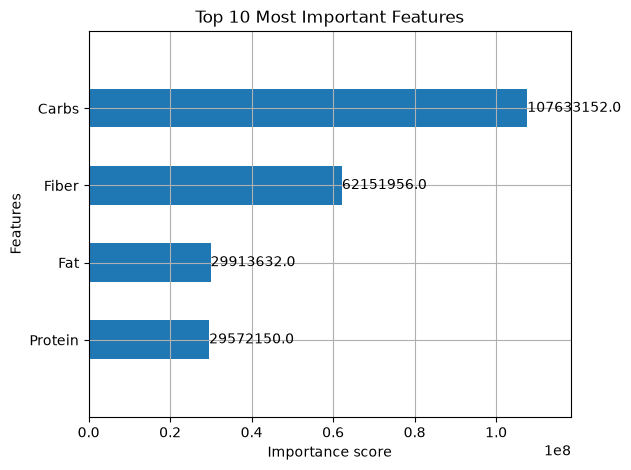

  [M1] done (train 924 meals / 34 participants, validation 215 meals / 9 participants)

M1 pooled out-of-fold results (0s):
   model target       variant     RMSE      MAE     R2  mean_participant_MAE
Baseline      - training_mean 3940.900 2958.698 -0.023              2847.182
   Ridge  y_raw           raw 3723.099 2741.599  0.087              2630.829
 XGBoost  y_raw           raw 3640.568 2718.076  0.127              2613.353

=== M2: 19 features, 1139 meals, 43 participants ===

Top 10 features with the largest coefficients:
pre_glucose_last         13941.014092
pre_glucose_mean         13876.144688
pre_glucose_slope         2354.234929
Carbs                      872.272202
hours_since_prev_food      777.889234
meal_breakfast             609.982768
pre_glucose_sd             513.621306
meal_lunch                 481.313067
Protein                    462.718990
meal_hour_sin              351.173655
dtype: float64


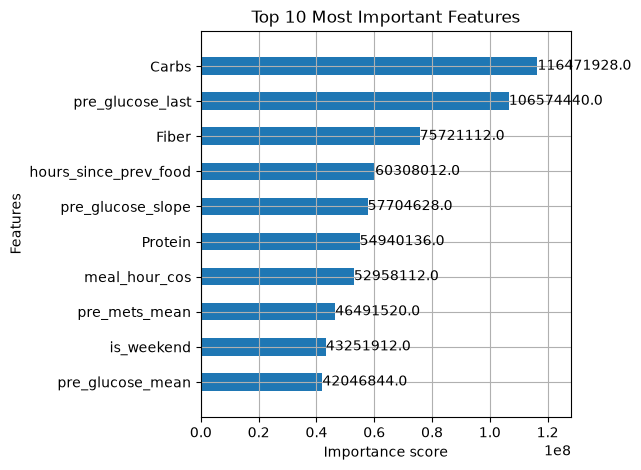

  [M2] done (train 924 meals / 34 participants, validation 215 meals / 9 participants)

M2 pooled out-of-fold results (0s):
   model target       variant     RMSE      MAE     R2  mean_participant_MAE
Baseline      - training_mean 3940.900 2958.698 -0.023              2847.182
   Ridge  y_raw           raw 3063.113 2282.874  0.382              2210.873
 XGBoost  y_raw           raw 3206.073 2314.332  0.323              2222.670

=== M3: 24 features, 1139 meals, 43 participants ===

Top 10 features with the largest coefficients:
pre_glucose_mean           11770.780091
pre_glucose_last           10946.221397
pre_glucose_slope           1699.562054
A1c PDL (Lab)                969.454318
Carbs                        948.471493
BMI                          640.785201
Insulin                      602.222936
Fasting GLU - PDL (Lab)      594.659891
meal_hour_sin                508.261819
hours_since_prev_food        458.805648
dtype: float64


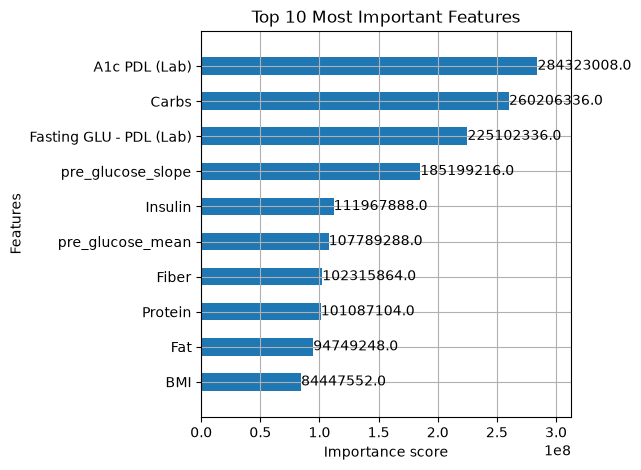

  [M3] done (train 924 meals / 34 participants, validation 215 meals / 9 participants)

M3 pooled out-of-fold results (1s):
   model target       variant     RMSE      MAE     R2  mean_participant_MAE
Baseline      - training_mean 3940.900 2958.698 -0.023              2847.182
   Ridge  y_raw           raw 3167.106 2466.798  0.339              2365.997
 XGBoost  y_raw           raw 3395.980 2438.884  0.240              2321.867

=== M3_gutmatched: 24 features, 1055 meals, 40 participants ===

Top 10 features with the largest coefficients:
pre_glucose_mean           13026.828937
pre_glucose_last           12137.935052
pre_glucose_slope           1917.063806
A1c PDL (Lab)               1058.527166
Carbs                        958.338358
Insulin                      570.435292
Fasting GLU - PDL (Lab)      546.393637
hours_since_prev_food        478.656414
BMI                          477.635442
meal_hour_sin                447.112481
dtype: float64


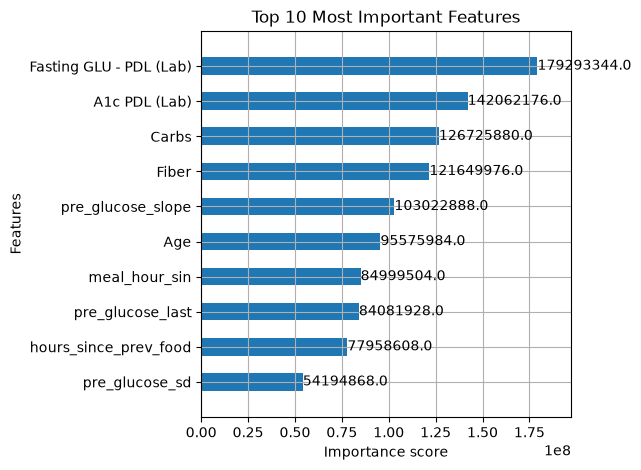

  [M3_gutmatched] done (train 840 meals / 31 participants, validation 215 meals / 9 participants)

M3_gutmatched pooled out-of-fold results (1s):
   model target       variant     RMSE      MAE     R2  mean_participant_MAE
Baseline      - training_mean 3935.068 2964.807 -0.020              2854.456
   Ridge  y_raw           raw 3235.397 2572.949  0.310              2478.750
 XGBoost  y_raw           raw 3263.781 2246.651  0.298              2124.286

=== M4: 46 features, 1055 meals, 40 participants ===

Top 10 features with the largest coefficients:
A1c PDL (Lab)                     399.310481
Carbs                             375.555312
Fasting GLU - PDL (Lab)           336.593769
pre_glucose_slope                 247.187909
Putrescine Production Pathways    186.212581
pre_glucose_sd                    167.913711
hours_since_prev_food             160.602763
Insulin                           157.674764
Age                               137.146570
meal_hour_sin                     131.8

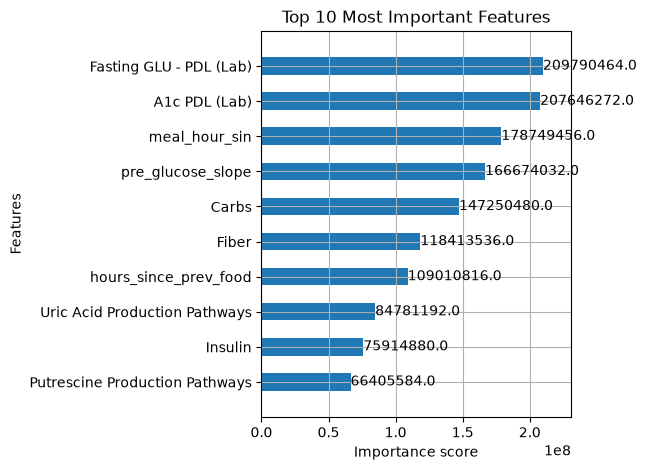

  [M4] done (train 840 meals / 31 participants, validation 215 meals / 9 participants)

M4 pooled out-of-fold results (1s):
   model target       variant     RMSE      MAE     R2  mean_participant_MAE
Baseline      - training_mean 3935.068 2964.807 -0.020              2854.456
   Ridge  y_raw           raw 3389.250 2468.911  0.243              2355.996
 XGBoost  y_raw           raw 3265.343 2270.070  0.297              2145.624

All runs finished in 0.0 min.


In [20]:
oof_tables, param_tables, set_summaries = [], [], []
t_start = time.time()

for set_name, columns in FEATURE_SETS.items():
    data = DATASETS[set_name]
    print(f"\n=== {set_name}: {len(columns)} features, {len(data)} meals, "
          f"{data['subject'].nunique()} participants ===")
    t0 = time.time()
    oof, params = run_cv(set_name, columns, data)
    oof_tables.append(oof)
#     param_tables.append(params)

    summary = summarize(oof)
    set_summaries.append(summary)
    print(f"\n{set_name} pooled out-of-fold results ({time.time() - t0:.0f}s):")
    print(summary[["model", "target", "variant", "RMSE", "MAE", "R2", "mean_participant_MAE" ]].round(3).to_string(index=False))

oof_predictions = pd.concat(oof_tables, ignore_index=True)
# best_params = pd.concat(param_tables, ignore_index=True)
metrics = pd.concat(set_summaries, ignore_index=True)
print(f"\nAll runs finished in {(time.time() - t_start) / 60:.1f} min.")

In [21]:
conditions = [
    data['A1c PDL (Lab)'] >= 6.5,
    data['A1c PDL (Lab)'] >= 5.7
]
choices = ['diabetes', 'prediabetes']

data['health_status'] = np.select(conditions, choices, default='healthy')

In [22]:
conditions = [
    bio['A1c PDL (Lab)'] >= 6.5,
    bio['A1c PDL (Lab)'] >= 5.7
]
choices = ['diabetes', 'prediabetes']
bio['health_status'] = np.select(conditions, choices, default='healthy')

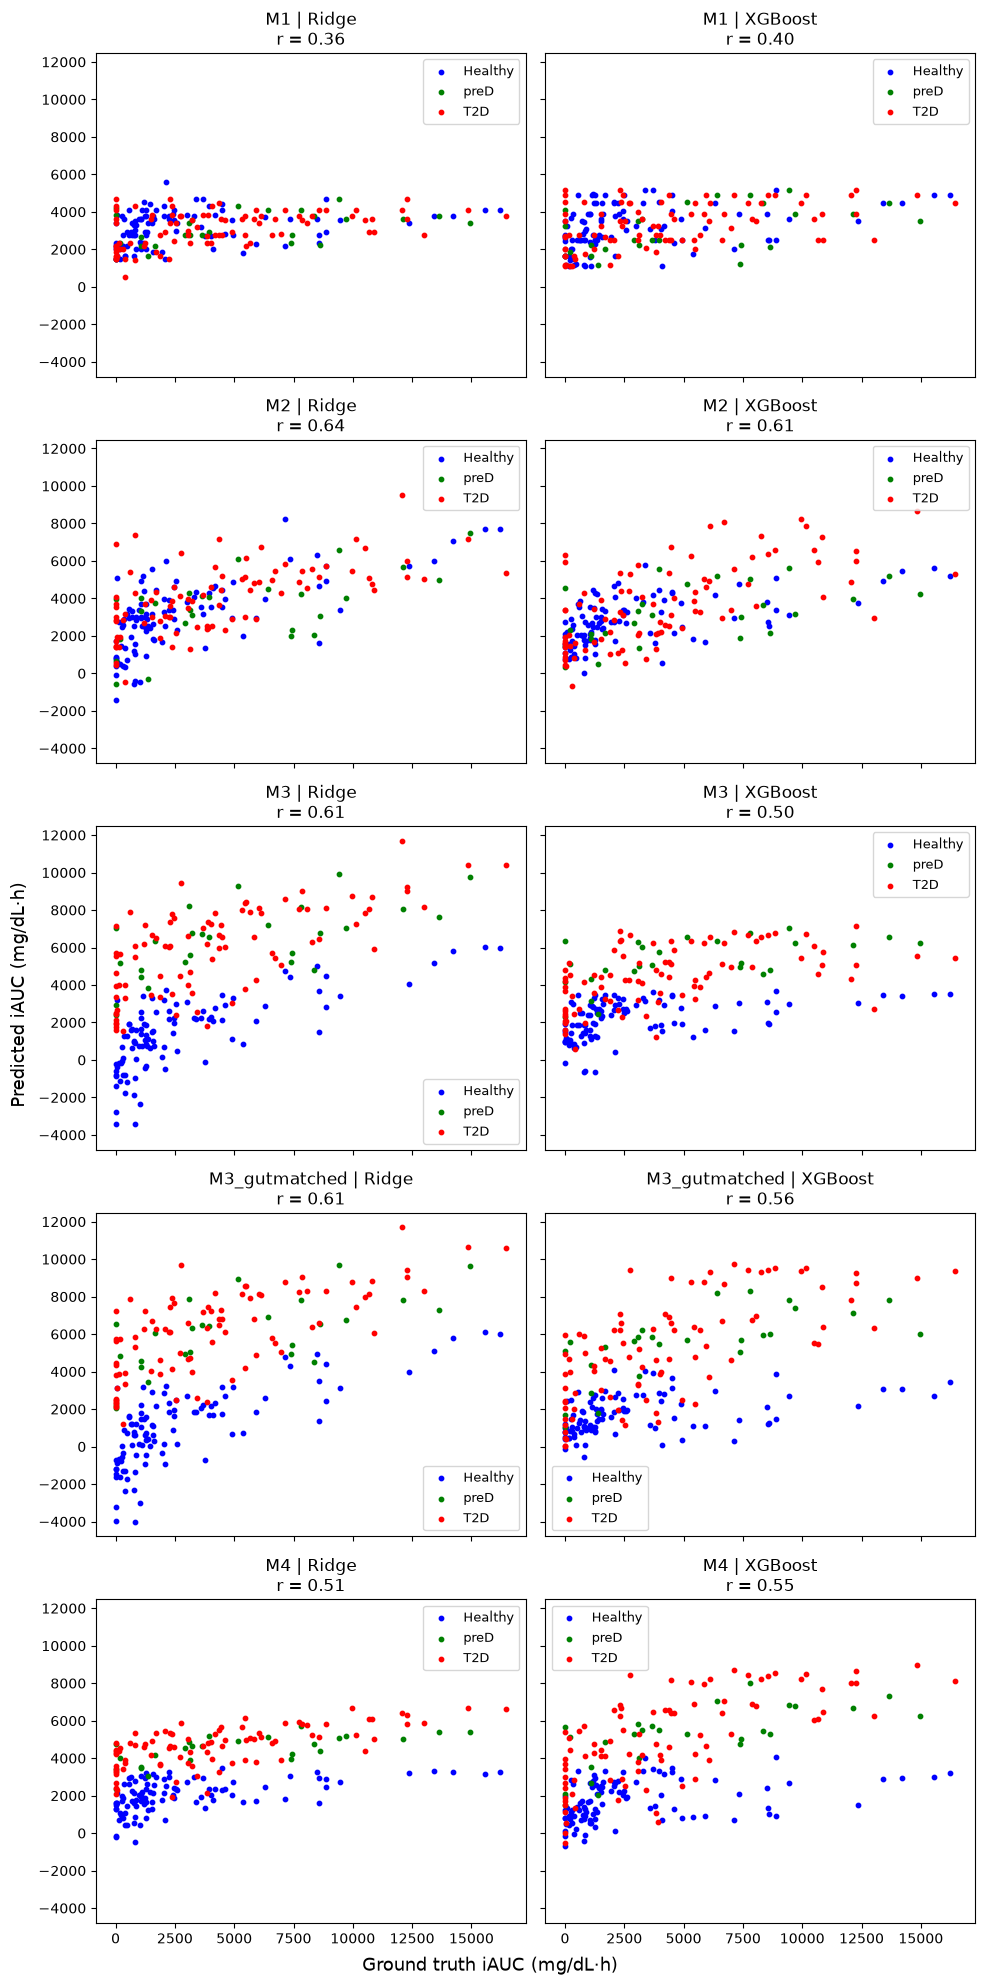

In [23]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

plot_data = oof_predictions.merge(
    bio[["subject", "health_status"]],
    on="subject",
    how="left",
    validate="many_to_one",
)

# Your current models use raw targets.
plot_data = plot_data[
    plot_data["variant"].isin(["raw", "training_mean"])
]

feature_sets = plot_data["feature_set"].drop_duplicates().tolist()
models = plot_data["model"].drop_duplicates().tolist()
models = models[1:]
fig, axes = plt.subplots(
    len(feature_sets), len(models),
    figsize=(5 * len(models), 4 * len(feature_sets)),
    sharex=True, sharey=True, squeeze=False,
)

for row, feature_set in enumerate(feature_sets):
    for col, model in enumerate(models):
        ax = axes[row, col]

        group = plot_data[
            (plot_data["feature_set"] == feature_set)
            & (plot_data["model"] == model)
        ]

        if group.empty:
            ax.set_visible(False)
            continue

        actual = group["y_true"].to_numpy() 
        predicted = group["y_pred"].to_numpy() 

        for status, color, label in [
            ("healthy", "blue", "Healthy"),
            ("prediabetes", "green", "preD"),
            ("diabetes", "red", "T2D"),
        ]:
            index = group["health_status"].eq(status).to_numpy()
            ax.scatter(
                actual[index], predicted[index],
                color=color, s=10, label=label,
            )

        if len(actual) >= 2 and np.ptp(actual) > 0 and np.ptp(predicted) > 0:
            correlation = f"{pearsonr(actual, predicted)[0]:.2f}"
        else:
            correlation = "undefined"

        ax.set_title(f"{feature_set} | {model}\nr = {correlation}")
        ax.legend(fontsize=9)

fig.supxlabel("Ground truth iAUC (mg/dL·h)", fontsize=13)
fig.supylabel("Predicted iAUC (mg/dL·h)", fontsize=13)
plt.tight_layout()
plt.show()

## 8. Results
Metrics are pooled out-of-fold, on the original mg/dL·min scale unless marked `_log`. Lower is better for RMSE, MAE, MedAE and participant MAE; higher is better for R² and Spearman ρ. `pct_participants_better_than_mean` is the share of participants whose own MAE beats the training-mean baseline. `target` says which outcome the model was trained on (`y_raw`, `y_log`, or `y_gamma = iAUC + 1`).

In [24]:
SET_ORDER = list(FEATURE_SETS)
metrics["feature_set"] = pd.Categorical(metrics["feature_set"], SET_ORDER, ordered=True)
metrics = metrics.sort_values(["feature_set", "model", "target", "variant"]).reset_index(drop=True)

print("Full results table (every set x model x target x back-transform):")
display(metrics.round(3))

# One row per set x run, using each run's primary back-transform
label_map = {(m, t, v): label for m, t, v, label in PRIMARY_RUNS}
primary = metrics[metrics.apply(lambda r: (r["model"], r["target"], r["variant"]) in label_map, axis=1)].copy()
primary["label"] = primary.apply(lambda r: label_map[(r["model"], r["target"], r["variant"])], axis=1)
baseline_rows = metrics[(metrics["model"] == "Baseline") & (metrics["variant"] == "training_mean")].copy()
baseline_rows["label"] = "Baseline (mean)"
primary = pd.concat([baseline_rows, primary], ignore_index=True)
COLUMN_ORDER = ["Baseline (mean)"] + RUN_LABELS

for column in ["R2", "RMSE", "MAE", "mean_participant_MAE"]:
    print(f"\n{column}  (rows = feature set, columns = model run):")
    print(primary.pivot(index="feature_set", columns="label", values=column)[COLUMN_ORDER]
          .round(3).to_string())

print("\n\n===== SCORES: y_raw vs y_log, same models =====")
for model in ["Ridge", "XGBoost"]:
    block = metrics[(metrics["model"] == model)
                    & (((metrics["target"] == "y_raw") & (metrics["variant"] == "raw")))]
    print(f"\n{model}:")
    display(block[["feature_set", "target", "variant", "RMSE", "MAE", "R2", "mean_participant_MAE",
                  "negative_predictions"]].round(3))

candidates = metrics[metrics["model"] != "Baseline"]
print("\nBest configuration per feature set (lowest MAE):")
display(candidates.loc[candidates.groupby("feature_set", observed=True)["MAE"].idxmin(),
                       ["feature_set", "model", "target", "variant", "RMSE", "MAE", "R2",
                        "mean_participant_MAE"]].round(3))

# print("\nSelected hyperparameters per outer fold (median across folds):")
# param_cols = [c for c in best_params.columns
#               if c not in ["feature_set", "fold", "model", "target", "inner_cv_score"]]
# display(best_params.groupby(["feature_set", "model", "target"])[param_cols]
#         .median(numeric_only=True).round(4))

Full results table (every set x model x target x back-transform):


,feature_set,model,target,variant,RMSE,MAE,R2,mean_participant_MAE,negative_predictions,pct_participants_better_than_mean
0,M1,Baseline,-,training_mean,3940.900,2958.698,-0.023,2847.182,0,0.000
1,M1,Ridge,y_raw,raw,3723.099,2741.599,0.087,2630.829,0,100.000
2,M1,XGBoost,y_raw,raw,3640.568,2718.076,0.127,2613.353,0,100.000
3,M2,Baseline,-,training_mean,3940.900,2958.698,-0.023,2847.182,0,0.000
4,M2,Ridge,y_raw,raw,3063.113,2282.874,0.382,2210.873,8,88.889
5,M2,XGBoost,y_raw,raw,3206.073,2314.332,0.323,2222.670,1,88.889
6,M3,Baseline,-,training_mean,3940.900,2958.698,-0.023,2847.182,0,0.000
7,M3,Ridge,y_raw,raw,3167.106,2466.798,0.339,2365.997,24,88.889
8,M3,XGBoost,y_raw,raw,3395.980,2438.884,0.240,2321.867,4,88.889
9,M3_gutmatched,Baseline,-,training_mean,3935.068,2964.807,-0.020,2854.456,0,0.000



R2  (rows = feature set, columns = model run):
label          Baseline (mean)  Ridge (raw)  XGBoost (raw)
feature_set                                               
M1                      -0.023        0.087          0.127
M2                      -0.023        0.382          0.323
M3                      -0.023        0.339          0.240
M3_gutmatched           -0.020        0.310          0.298
M4                      -0.020        0.243          0.297

RMSE  (rows = feature set, columns = model run):
label          Baseline (mean)  Ridge (raw)  XGBoost (raw)
feature_set                                               
M1                    3940.900     3723.099       3640.568
M2                    3940.900     3063.113       3206.073
M3                    3940.900     3167.106       3395.980
M3_gutmatched         3935.068     3235.397       3263.781
M4                    3935.068     3389.250       3265.343

MAE  (rows = feature set, columns = model run):
label          Baseline (me

,feature_set,target,variant,RMSE,MAE,R2,mean_participant_MAE,negative_predictions
1,M1,y_raw,raw,3723.099,2741.599,0.087,2630.829,0
4,M2,y_raw,raw,3063.113,2282.874,0.382,2210.873,8
7,M3,y_raw,raw,3167.106,2466.798,0.339,2365.997,24
10,M3_gutmatched,y_raw,raw,3235.397,2572.949,0.310,2478.750,27
13,M4,y_raw,raw,3389.250,2468.911,0.243,2355.996,3



XGBoost:


,feature_set,target,variant,RMSE,MAE,R2,mean_participant_MAE,negative_predictions
2,M1,y_raw,raw,3640.568,2718.076,0.127,2613.353,0
5,M2,y_raw,raw,3206.073,2314.332,0.323,2222.670,1
8,M3,y_raw,raw,3395.980,2438.884,0.240,2321.867,4
11,M3_gutmatched,y_raw,raw,3263.781,2246.651,0.298,2124.286,2
14,M4,y_raw,raw,3265.343,2270.070,0.297,2145.624,6



Best configuration per feature set (lowest MAE):


,feature_set,model,target,variant,RMSE,MAE,R2,mean_participant_MAE
2,M1,XGBoost,y_raw,raw,3640.568,2718.076,0.127,2613.353
4,M2,Ridge,y_raw,raw,3063.113,2282.874,0.382,2210.873
8,M3,XGBoost,y_raw,raw,3395.980,2438.884,0.240,2321.867
11,M3_gutmatched,XGBoost,y_raw,raw,3263.781,2246.651,0.298,2124.286
14,M4,XGBoost,y_raw,raw,3265.343,2270.070,0.297,2145.624


In [25]:
# ---- Participant-level paired bootstrap comparisons ---------------------------------
RUN_KEYS = {label: (m, t, v) for m, t, v, label in PRIMARY_RUNS}


def participant_mae(feature_set, label):
    model, target, variant = RUN_KEYS[label]
    block = oof_predictions[(oof_predictions["feature_set"] == feature_set)
                            & (oof_predictions["model"] == model)
                            & (oof_predictions["target"] == target)
                            & (oof_predictions["variant"] == variant)]
    return (block["y_true"] - block["y_pred"]).abs().groupby(block["subject"]).mean()


def bootstrap_delta(new, old, n_boot=2000):
    """Mean paired difference (new - old) of participant MAE; negative = new is better."""
    common = new.index.intersection(old.index)
    delta = (new.loc[common] - old.loc[common]).to_numpy()
    rng = np.random.default_rng(SEED)
    boots = np.array([rng.choice(delta, size=len(delta), replace=True).mean() for _ in range(n_boot)])
    return {"participants": len(common), "mean_delta_MAE": delta.mean(),
            "ci_low": np.percentile(boots, 2.5), "ci_high": np.percentile(boots, 97.5),
            "participants_improved": int((delta < 0).sum())}


# 1) Does the log target help? (log vs raw, same model and feature set)
# rows = []
# for set_name in SET_ORDER:
#     for model in ["Ridge", "XGBoost"]:
#         rows.append({"feature_set": set_name, "model": model, "comparison": "log vs raw",
#                      **bootstrap_delta(participant_mae(set_name, f"{model} (raw)"))})
# print("Change in participant MAE from training on y_log instead of y_raw (negative = log better):")
# display(pd.DataFrame(rows).round(2))

# 2) Does each added feature block help? (per model run)
steps = [("M1", "M2"), ("M2", "M3"), ("M3_gutmatched", "M4")]
rows = []
for old_set, new_set in steps:
    for label in RUN_LABELS:
        rows.append({"comparison": f"{old_set} -> {new_set}", "run": label,
                     **bootstrap_delta(participant_mae(new_set, label), participant_mae(old_set, label))})
comparison_table = pd.DataFrame(rows)
print("\nChange in participant MAE when a feature block is added (negative = improvement):")
display(comparison_table.round(2))


Change in participant MAE when a feature block is added (negative = improvement):


,comparison,run,participants,mean_delta_MAE,ci_low,ci_high,participants_improved
0,M1 -> M2,Ridge (raw),9,-419.96,-731.99,-160.85,8
1,M1 -> M2,XGBoost (raw),9,-390.68,-599.52,-191.67,8
2,M2 -> M3,Ridge (raw),9,155.12,-195.60,552.35,4
3,M2 -> M3,XGBoost (raw),9,99.20,-159.37,342.77,3
4,M3_gutmatched -> M4,Ridge (raw),9,-122.75,-424.85,170.16,5
5,M3_gutmatched -> M4,XGBoost (raw),9,21.34,-35.11,74.45,5


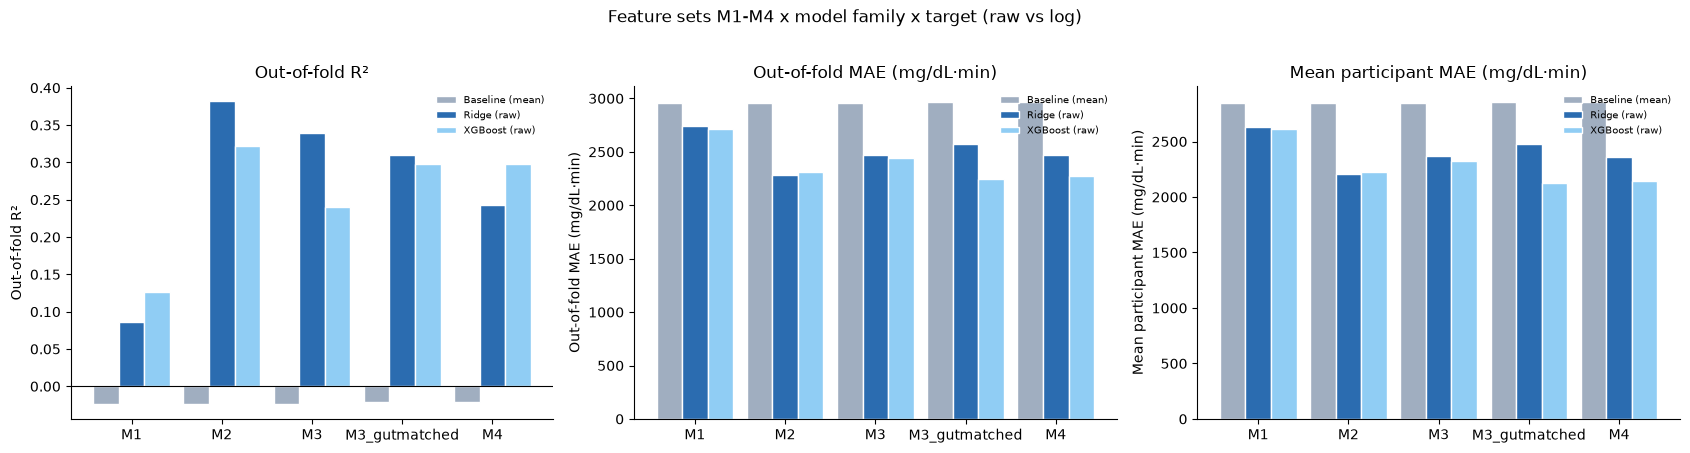

Saved to /Users/pavithraa/Desktop/BME_Data_Science/Project/Glucose-macros-data/cgmacros-code/cgmacros-data/code_openai/results_log_target : ['best_hyperparameters.csv', 'feature_block_comparisons.csv', 'feature_set_overview.csv', 'metrics_all.csv', 'model_dataframe.csv', 'oof_predictions.csv', 'performance_by_feature_set_and_model.png']


In [26]:
import matplotlib.pyplot as plt

colors = dict(zip(COLUMN_ORDER, ["#a0aec0", "#2b6cb0", "#90cdf4", "#2f855a", "#9ae6b4", "#dd6b20"]))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (column, label) in zip(axes, [("R2", "Out-of-fold R²"), ("MAE", "Out-of-fold MAE (mg/dL·min)"),
                                      ("mean_participant_MAE", "Mean participant MAE (mg/dL·min)")]):
    table = primary.pivot(index="feature_set", columns="label", values=column)[COLUMN_ORDER].loc[SET_ORDER]
    table.plot.bar(ax=ax, color=[colors[c] for c in COLUMN_ORDER], width=0.85, edgecolor="white")
    ax.set(xlabel="", ylabel=label, title=label)
    ax.tick_params(axis="x", rotation=0)
    ax.spines[["top", "right"]].set_visible(False)
    if column == "R2":
        ax.axhline(0, color="black", lw=0.8)
    ax.legend(frameon=False, fontsize=7)
fig.suptitle("Feature sets M1-M4 x model family x target (raw vs log)", y=1.02)
fig.tight_layout()
fig.savefig(OUT_DIR / "performance_by_feature_set_and_model.png", dpi=300, bbox_inches="tight")
plt.show()

metrics.to_csv(OUT_DIR / "metrics_all.csv", index=False)
oof_predictions.to_csv(OUT_DIR / "oof_predictions.csv", index=False)
# best_params.to_csv(OUT_DIR / "best_hyperparameters.csv", index=False)
comparison_table.to_csv(OUT_DIR / "feature_block_comparisons.csv", index=False)
overview.to_csv(OUT_DIR / "feature_set_overview.csv", index=False)
print("Saved to", OUT_DIR.resolve(), ":", sorted(p.name for p in OUT_DIR.iterdir()))

In [43]:
feature_sets

['M1', 'M2', 'M3', 'M3_gutmatched', 'M4']

In [48]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

for set_name, columns in FEATURE_SETS.items():
    data = DATASETS[set_name]
    print(f"\n=== {set_name}: {len(columns)} features, {len(data)} meals, "
          f"{data['subject'].nunique()} participants ===")
    
    # Drop rows with missing values in the selected features
    X = data[columns].dropna().to_numpy()
    
    # Standardize the features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Initialize and fit PCA
    pca = PCA(n_components=4)  # You can adjust the number of components as needed
    X_pca = pca.fit_transform(X_scaled)
    
    # Get PCA loadings (eigenvectors)
    pca_loadings = pd.DataFrame(pca.components_.T, index=columns, columns=[f'PC{i+1}' for i in range(pca.n_components_)])
    
    # Sort and display the top 10 loadings for the first principal component
    top_10_loadings = pca_loadings['PC1'].abs().sort_values(ascending=False).head(10)
    
    print(f"\nTop 10 PCA Loadings for {set_name} (PC1):")
    display(top_10_loadings.round(4))




=== M1: 4 features, 1139 meals, 43 participants ===

Top 10 PCA Loadings for M1 (PC1):


Fat        0.5757
Carbs      0.5379
Protein    0.4476
Fiber      0.4229
Name: PC1, dtype: float64


=== M2: 19 features, 1139 meals, 43 participants ===

Top 10 PCA Loadings for M2 (PC1):


meal_breakfast           0.4346
meal_hour_sin            0.4133
hours_since_prev_food    0.4058
pre_activity_z           0.2836
pre_mets_mean            0.2833
pre_actcal_mean          0.2724
Fiber                    0.2605
meal_dinner              0.2270
pre_hr_mean              0.1810
meal_lunch               0.1700
Name: PC1, dtype: float64


=== M3: 24 features, 1139 meals, 43 participants ===

Top 10 PCA Loadings for M3 (PC1):


meal_breakfast           0.4008
meal_hour_sin            0.3890
hours_since_prev_food    0.3745
pre_mets_mean            0.3089
pre_activity_z           0.3068
pre_actcal_mean          0.3039
Fiber                    0.2342
meal_dinner              0.2166
pre_hr_mean              0.2154
meal_lunch               0.1469
Name: PC1, dtype: float64


=== M3_gutmatched: 24 features, 1055 meals, 40 participants ===

Top 10 PCA Loadings for M3_gutmatched (PC1):


meal_breakfast           0.3789
meal_hour_sin            0.3690
hours_since_prev_food    0.3530
pre_mets_mean            0.3343
pre_activity_z           0.3327
pre_actcal_mean          0.3306
pre_hr_mean              0.2528
Fiber                    0.2260
meal_dinner              0.2097
BMI                      0.1461
Name: PC1, dtype: float64


=== M4: 46 features, 1055 meals, 40 participants ===

Top 10 PCA Loadings for M4 (PC1):


Microbiome-Induced Stress         0.3068
Butyrate Production Pathways      0.2909
Putrescine Production Pathways    0.2825
Bile Acid Metabolism Pathways     0.2662
Protein Fermentation              0.2572
Gut Microbiome Health             0.2512
Inflammatory Activity             0.2412
Flagellar Assembly Pathways       0.2381
Active Microbial Diversity        0.2354
Digestive Efficiency              0.2294
Name: PC1, dtype: float64

In [52]:
M1 = macro_columns
M2 = M1 + premeal_cols + activity_cols + meal_context_cols
M3 = M2 + health_columns
M4 = M3 + gut_features

# 1. Sample dataset (100 samples, 5 features)
X = model_df[health_columns].dropna().to_numpy()  # Using M1 features as an example

# 2. Standardize the features (mean = 0, variance = 1)
# PCA is sensitive to feature scales, so scaling first is critical
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Initialize and fit PCA
# Option A: Specify exact number of components
pca = PCA(n_components=4)
# Option B: Retain a percentage of variance (e.g., 95%)
# pca = PCA(n_components=0.95)

X_pca = pca.fit_transform(X_scaled)

pca_loadings = pd.Series(pca.components_[0], index=model_df[health_columns].columns)

# sort and display the loadings
top_10_loadings = pca_loadings.abs().sort_values(ascending=False).head(10)

# 4. Inspect the results
print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:", sum(pca.explained_variance_ratio_))

print("\nPCA Loadings (Eigenvectors * sqrt(explained_variance)):")
display(top_10_loadings.round(4))

Original shape: (1139, 5)
Reduced shape: (1139, 4)
Explained variance ratio: [0.46711058 0.29023806 0.14744086 0.07170595]
Total variance retained: 0.9764954559246526

PCA Loadings (Eigenvectors * sqrt(explained_variance)):


A1c PDL (Lab)              0.5880
Fasting GLU - PDL (Lab)    0.5622
Age                        0.3683
Insulin                    0.3360
BMI                        0.2994
dtype: float64